In [1]:
import pandas as pd

df = pd.read_csv("data.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [4]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [5]:
df = df.dropna()

In [6]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [7]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64

## Churn Distribution Analysis

Approximately 26.6% of customers have churned, while 73.4% have remained.

This indicates that a significant portion of customers are leaving the service, which could negatively impact revenue. Reducing churn should be a priority for the company.

In [8]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


In [9]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index")

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887228,0.112772
Two year,0.971513,0.028487


## Churn by Contract Type

Analyzing churn across different contract types helps identify whether contract duration influences customer retention.

## Churn by Contract Type - Key Insight

Customers with month-to-month contracts have the highest churn rate (~43%), while customers with longer-term contracts (one-year and two-year) have significantly lower churn rates (~11% and ~3% respectively).

This suggests that contract length is a strong factor influencing customer retention. Encouraging customers to switch to longer-term contracts could help reduce churn.

In [2]:
import pandas as pd

df = pd.read_csv("data.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()

## Visualization: Churn by Contract Type

This chart compares churn across different contract types. It helps visualize whether customers with shorter contracts are more likely to leave the company.

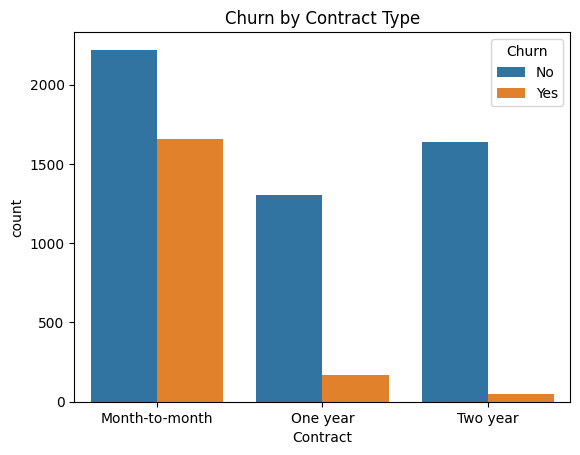

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn by Contract Type")
plt.show()

## Visualization Insight

The chart clearly shows that customers with month-to-month contracts have the highest churn rate. In contrast, customers with one-year and two-year contracts are much more likely to stay.

This reinforces the idea that longer contract commitments improve customer retention.

## Monthly Charges vs Churn

This analysis explores whether customers with higher monthly charges are more likely to churn.

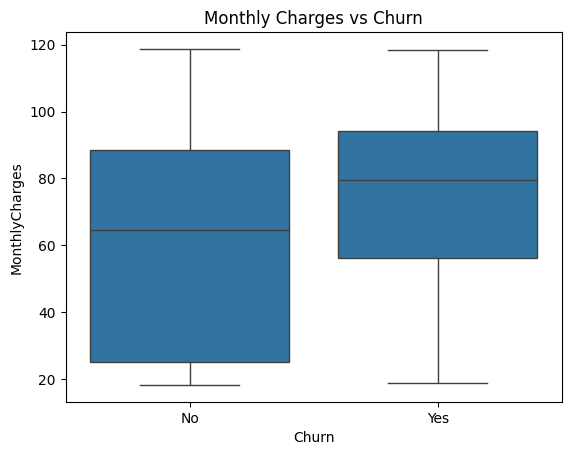

In [4]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

## Monthly Charges Insight

The boxplot shows that customers who churn generally have higher monthly charges compared to those who stay.

This suggests that higher pricing may contribute to customer dissatisfaction and increase the likelihood of churn.

## Tenure vs Churn

This analysis examines whether customers with shorter tenure (new customers) are more likely to churn.

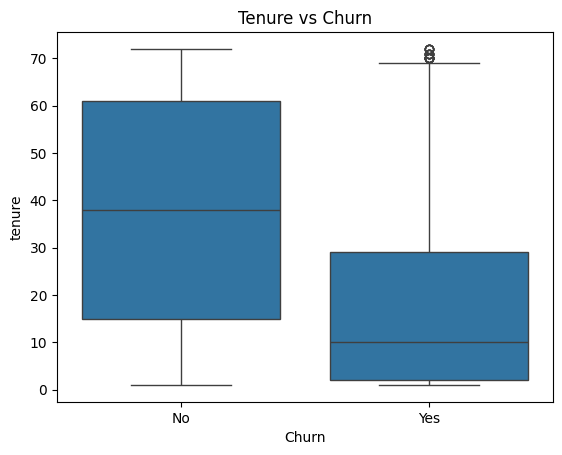

In [6]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.show()

## Tenure Insight

The analysis shows that customers who churn tend to have significantly shorter tenure compared to those who remain.

This suggests that new customers are more likely to leave, highlighting the importance of improving early customer experience and onboarding.

## Key Findings

The analysis reveals that customer churn is strongly influenced by contract type, monthly charges, and tenure.

Customers who are on month-to-month contracts, have higher monthly charges, and have shorter tenure are the most likely to churn.

These insights suggest that improving early customer experience, offering incentives for long-term contracts, and reviewing pricing strategies could help reduce churn.

## Preparing Data for Machine Learning

Before training a churn prediction model, the dataset must be prepared for machine learning.

This includes:
- removing irrelevant identifiers
- converting categorical variables into numeric format
- separating input features from the target variable

In [7]:
# make a copy for modeling
model_df = df.copy()

# drop customerID because it is just an identifier
model_df = model_df.drop("customerID", axis=1)

# convert target column Churn from Yes/No to 1/0
model_df["Churn"] = model_df["Churn"].map({"Yes": 1, "No": 0})

# convert categorical columns into numeric variables
model_df = pd.get_dummies(model_df, drop_first=True)

# preview transformed data
model_df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [8]:
model_df = model_df.astype(int)

## Train-Test Split

The dataset is divided into training and testing sets to evaluate the performance of the machine learning model on unseen data.

In [9]:
from sklearn.model_selection import train_test_split

# separate features and target
X = model_df.drop("Churn", axis=1)
y = model_df["Churn"]

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


## Logistic Regression Model

A logistic regression model is used to predict whether a customer will churn based on their features.

This model is commonly used for binary classification problems like churn prediction.

In [10]:
from sklearn.linear_model import LogisticRegression

# create model
model = LogisticRegression(max_iter=1000)

# train model
model.fit(X_train, y_train)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [11]:
y_pred = model.predict(X_test)

In [12]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7867803837953091
              precision    recall  f1-score   support

           0       0.83      0.88      0.86      1033
           1       0.62      0.52      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



## Model Evaluation

The logistic regression model is evaluated using accuracy and classification metrics to assess its performance in predicting customer churn.

The logistic regression model achieved an accuracy of approximately 79%, indicating a good overall performance in predicting customer churn.

While the model performs well overall, it is less effective at identifying customers who churn, with a recall of 52%. This suggests that the model may miss a significant number of at-risk customers.

Improving churn detection should be a priority, as failing to identify these customers could result in lost revenue.

## Business Interpretation

From a business perspective, correctly identifying customers who are likely to churn is more important than overall accuracy. 

Although the model performs well overall, improving the recall for churn prediction would allow the company to proactively retain more customers and reduce revenue loss.

## Model Improvement

To improve the logistic regression model, feature scaling is applied. This helps the model converge better and can improve performance, especially when features are on different numerical scales.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# train improved logistic regression model
improved_model = LogisticRegression(max_iter=2000, class_weight="balanced")
improved_model.fit(X_train_scaled, y_train)

# predictions
y_pred_improved = improved_model.predict(X_test_scaled)

# evaluation
print("Improved Accuracy:", accuracy_score(y_test, y_pred_improved))
print(classification_report(y_test, y_pred_improved))

Improved Accuracy: 0.7313432835820896
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1033
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.75      1407



## Improved Model Evaluation

After applying feature scaling and class balancing, the model's ability to detect churn improved significantly.

The recall for churn increased from 52% to 79%, meaning the model can now identify a much larger portion of customers who are likely to leave.

Although overall accuracy decreased slightly, this trade-off is acceptable because detecting at-risk customers is more valuable from a business perspective.

In [15]:
import joblib

joblib.dump(improved_model, "model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

## Saving the Model

The trained model and scaler are saved so they can be reused in a Streamlit application without retraining.

In [16]:
import joblib

joblib.dump(X.columns.tolist(), "columns.pkl")

['columns.pkl']